# DS 2002 Midterm Project

Libraries

In [64]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import sqlite3 as sql
import datetime as dt
import matplotlib.dates as mdates
import plotly.express as px
import plotly.graph_objects as go
import re
import pandas as pd, numpy as np, requests, time

Raw Data Files

In [65]:
# CSV Files
store_locations = 'https://raw.githubusercontent.com/Fespinoza1477/walmart-hurricane-project/main/Data/store_locations.csv'
transactions = 'https://raw.githubusercontent.com/Fespinoza1477/walmart-hurricane-project/main/Data/walmart_transactions.csv'
distribution_center = 'https://raw.githubusercontent.com/Fespinoza1477/walmart-hurricane-project/main/Data/distribution_centers.csv'
product_catalog = 'https://raw.githubusercontent.com/Fespinoza1477/walmart-hurricane-project/main/Data/product_catalog.csv'
# Database File
!wget -O walmart.db "https://raw.githubusercontent.com/Fespinoza1477/walmart-hurricane-project/main/Data/inventory_and_sales.db"
conn = sql.connect("walmart.db")


# Tables from CSV Files
loc = pd.read_csv(store_locations)
trans = pd.read_csv(transactions)
dist = pd.read_csv(distribution_center)
cat = pd.read_csv(product_catalog)

# Tables from database file
inv_levels_db = pd.read_sql("SELECT * FROM inventory_levels;", conn)
daily_sales_db = pd.read_sql("SELECT * FROM daily_sales_summary;", conn)

--2026-10-25 22:05:48--  https://raw.githubusercontent.com/Fespinoza1477/walmart-hurricane-project/main/Data/inventory_and_sales.db
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 352256 (344K) [application/octet-stream]
Saving to: ‘walmart.db’

walmart.db          100%[===================>] 344.00K  --.-KB/s    in 0.03s   

2026-10-25 22:05:49 (10.1 MB/s) - ‘walmart.db’ saved [352256/352256]



Cleaning

In [66]:
# Profile on the tables
def profile(df, name=None):
    """Return a summary of dtypes, null counts, null percentages, and unique counts."""
    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "null_count": df.isna().sum(),
        "null_pct": (df.isna().mean() * 100).round(2),
        "unique": df.nunique(),
    })
    if name:
        print(f"{name}: {df.shape[0]:,} rows x {df.shape[1]} columns")
    return summary

tables = {"loc": loc, "trans": trans, "dist": dist, "cat": cat, "inv_levels_db":inv_levels_db, "daily_sales_db": daily_sales_db}

for name, df in tables.items():
    display(profile(df, name))
    print()


loc: 14 rows x 8 columns


,dtype,null_count,null_pct,unique
store_id,object,0,0.00,14
store_name,object,0,0.00,12
city,object,0,0.00,12
state,object,0,0.00,3
zip_code,int64,0,0.00,12
latitude,float64,1,7.14,11
longitude,float64,1,7.14,11
region,object,0,0.00,7



trans: 25,562 rows x 8 columns


,dtype,null_count,null_pct,unique
transaction_id,object,0,0.00,25532
store_id,object,0,0.00,60
timestamp,object,886,3.47,23952
sku,object,0,0.00,45
product_name,object,0,0.00,63
category,object,0,0.00,37
quantity,int64,0,0.00,11
unit_price,object,0,0.00,3668



dist: 5 rows x 8 columns


...

,dtype,null_count,null_pct,unique
sku,object,0,0.00,45
product_name,object,0,0.00,38
category,object,0,0.00,27
subcategory,object,13,28.89,19
unit_cost,float64,5,11.11,40
supplier,object,0,0.00,14
package_size,object,0,0.00,15



inv_levels_db: 4,320 rows x 6 columns


,dtype,null_count,null_pct,unique
date,object,0,0.00,30
store_id,object,0,0.00,12
sku,object,0,0.00,49
units_on_hand,int64,0,0.00,196
units_on_order,float64,626,14.49,101
reorder_point,int64,0,0.00,31



daily_sales_db: 3,600 rows x 5 columns


,dtype,null_count,null_pct,unique
date,object,0,0.0,60
store_id,object,0,0.0,12
category,object,0,0.0,10
total_units,float64,0,0.0,285
total_revenue,float64,0,0.0,3552


In [67]:
# Store Location Cleaning

# Normalizing spelling of Florida to FLORIDA
loc["state"] = (
    loc["state"]
    .astype(str)
    .str.upper()
    .str.strip()
    .str.replace(".","", regex=False)
)
state_map = {
    "FLORIDA":"FLORIDA",
    "FLA":"FLORIDA",
    "FL":"FLORIDA",
}
loc["state"]=loc["state"].replace(state_map)

# Fixing store_id to drop duplicates
id_fix = {
    "FL239":"FL-239",
    "FL_287":"FL-287",
}
loc["store_id"]=loc["store_id"].replace(id_fix)
loc = loc.drop_duplicates(subset="store_id", keep="first").reset_index(drop=True)

In [68]:
# Distribution Cleaning

# Removing "~" and converting "surge_capacity" to Int64
dist["surge_capacity"] = (
    pd.to_numeric(dist["surge_capacity"].astype(str).str.replace("~", "", regex=False), errors="coerce")
    .astype("Int64")
)

# Need to make a decision on what to do for missing cost/shipment for DC-BHM

In [69]:
# Product Catalog Cleaning and SKU Mapping

# Cleaning category by normalizing case and consolidating category labels
cat["category"] = (
    cat["category"].str.strip().str.lower()
    .str.title()
)

category_map = {
        "Breakfast Foods": "Breakfast",
        "Emergency Supplies": "Emergency",
        "Alcoholic Beverages": "Alcohol",
        "Groceries": "Grocery",
        "Baby": "Baby Products",
        "Games & Entertainment":"Entertainment",
        "Household Essentials":"Household",
        "Health & Wellness":"Health",
}
cat["category"]=cat["category"].replace(category_map)

# SKU mapping. SKUs will be consolidated based on product name, ignoring all other columns such as cost, supplier and package size
sku_map = {
        'PT-12':'POPTART-STRAW',
        'SKU#459812':'POPTART-STRAW',
        'POPTART-STRAW':'POPTART-STRAW',
        'PT_STRAWBERRY':'POPTART-STRAW',
        'WTR-24':'WATER24PK',
        'WATER24PK':'WATER24PK',
        'WTR_24PK':'WATER24PK',
        'BATT-100': 'BAT-AA4',
        'BAT-AA4':'BAT-AA4',
        'BATT_AA_4PK':'BAT-AA4',
        'FLASH-01': 'LED-FLASH',
        'LED-FLASH': 'LED-FLASH',
        'BEER-24': 'BEER-24',
        'LTBEER24': 'BEER-24',
        'BG-MONO': 'GAME-MONO',
        'MONOPOLY-01': 'GAME-MONO',
        'GAME-MONO': 'GAME-MONO',
        'CARDS-01':'CARDS-01',
        'PLAYCARD-STD':'CARDS-01',
        'STREAM-01':'STREAM-01',
        'ROKU-STD':'STREAM-01',
        'SOUP-CAN':'SOUP',
        'CNSOUP-01':'SOUP',
        'BREAD-WH': 'WHITEBREAD',
        'WHITEBREAD': 'WHITEBREAD',
        'PB-16': "PNUTBTR",
        'PNUTBTR-16': "PNUTBTR",
        'CNDL-EM': "EMERG-CNDL",
        'CANDLE-EMRG': "EMERG-CNDL",
        'FAID-01': 'FIRSTAID-KIT',
        'FIRSTAID-KIT': 'FIRSTAID-KIT',
        'CHRG-PORT': 'CHRGR',
        'PORTCHARGER': 'CHRGR',
        'CHIPS-VP': "CHIPS-VP",
        'CHIPVARIETY': "CHIPS-VP",
        'PTOWEL-6': 'PTOWEL',
        'PAPERTOWEL6': 'PTOWEL',
        'TP-12': 'TOILETPAPER',
        'TOILETPAPER12': 'TOILETPAPER',
        'DIAP-S3':'DIAPERS',
        'DIAPERS-3':'DIAPERS',
        'BFORM-01':'BABYFORM',
        'BABYFORMULA':'BABYFORM',
        'TARP-HD': 'TARP-HD',
        'HDTARP-01': 'TARP-HD',
}
cat["sku"]=cat["sku"].replace(sku_map)

# Normalizing product_name. This also has functionality for the transaction data
groups = {
    "Pop-Tarts Strawberry":   ["pop-tarts strawberry", "Strawberry Pop-Tart", 'Pop Tarts Strawberry',"Pop-Tarts Strawberry",'POPTART-STRAWBERRY', 'Pop Tarts - Strawberry'],
    "Bottled Water 24-Pack":  ["BOTTLED WATER 24PK", "Bottled Water 24-Pack", "Water - 24 Pack"],
    "AA Batteries 4-Pack":    ["BATTERIES AA 4PK", "AA Batteries 4-Pack",'AA Batteries (4-pack)'],
    "LED Flashlight":         ["FLASHLIGHT LED", "LED Flashlight",'Flashlight - LED'],
    "Light Beer 24-Pack":     ["Light Beer (24-pack)", "Light Beer 24-Pack",'Light Beer 24pk','BEER LIGHT 24PK'],
    "Roku Streaming Stick":   ["Roku Streaming Stick", "Streaming Device",'STREAMING STICK'],
    "Monopoly Board Game":    ["Monopoly Board Game", "Board Game - Monopoly",'MONOPOLY'],
    "Playing Cards":          ["Playing Cards", "PLAYING CARDS",'Standard Playing Cards'],
    "Canned Soup":            ["Soup - Canned", "Canned Soup",'CANNED SOUP'],
    "White Bread":            ["WHITE BREAD", "White Bread",'Bread - White'],
    "Peanut Butter":          ["PEANUT BUTTER", "Peanut Butter",'Peanut Butter 16oz'],
    "Emergency Candles":      ["Candles (Emergency)", "Emergency Candles",'CANDLES - EMERGENCY'],
    "First Aid Kit":          ["First-Aid Kit", "First Aid Kit",'FIRST AID KIT'],
    "Portable Phone Charger": ["PORTABLE CHARGER", "Portable Phone Charger",'Phone Charger - Portable'],
    "Chips Variety Pack":     ["Variety Pack - Chips", "Chips Variety Pack",'CHIPS VARIETY PACK'],
    "Paper Towels":           ["Paper Towels",  'PAPER TOWELS 6PK','Paper Towels 6-Roll'],
    "Toilet Paper 12-Roll":   ["TOILET PAPER 12PK", "Toilet Paper 12-Roll",'TP 12 Pack'],
    "Baby Diapers - Size 3":  ["Baby Diapers - Size 3", "DIAPERS SZ 3",'Diapers Size 3'],
    "Baby Formula":           ["Infant Formula", "Baby Formula", 'BABY FORMULA'],
    "Heavy Duty Tarp":        ["Heavy Duty Tarp", "TARP - HEAVY DUTY",'HD Tarp'],
}


name_map = {variant: canon for canon, variants in groups.items() for variant in variants}
cat["product_name"] = cat["product_name"].str.strip().map(name_map)

# Converting package_size to Int64. For the entries with <NA>, they were formerly "bundle", which is not clear on how large the package size is.
size = cat["package_size"].str.strip().str.lower().replace({"single": "1", "bundle": pd.NA})
cat["package_size"] = size.str.extract(r"(\d+)", expand=False).astype("Int64")

# Need to decide on what to do with NaN in the "unit_cost" column


In [70]:
# Transaction data cleaning

# Dropping duplicates based on transaction ID
trans = trans.drop_duplicates(subset="transaction_id", keep="first").reset_index(drop=True)

# Cleaning category by normalizing case and consolidating category labels
trans["category"] = (
    trans["category"].str.strip().str.lower()
    .str.title()
)
trans["category"]=trans["category"].replace(category_map)


# SKU map
trans["sku"]=trans["sku"].replace(sku_map)


# product names
trans["product_name"] = trans["product_name"].str.strip().map(name_map)
trans.isna().sum()

# store_id
canonical = ['FL-239','FL-105','FL-330','FL-412','FL-287','FL-156',
             'FL-501','FL-078','FL-619','FL-445','FL-302','FL-710']

def clean_code(code):
    m = re.fullmatch(r"FL[-_]?(\d{3})", str(code).strip().upper())
    return f"FL-{m.group(1)}" if m else None

trans["store_id"] = trans["store_id"].map(clean_code)

# converting unit price to float by dropping $
trans["unit_price"] = (
    pd.to_numeric(trans["unit_price"].astype(str).str.replace("$", "", regex=False), errors="coerce")
    .astype("Float64")
)



# converting timestamp to datetime. Michael proposes that we drop rows with NaN for timestamp.
# The rows are useless because they cannot help identify trends. Its just under 900 rows, so thats a lot of data getting axed.
# Debating whether or not to replace the "timestamp" column with simply "date". Both are in datetime fornmat
ts = trans["timestamp"].str.strip().replace(
    {"": None, "NULL": None, "N/A": None, "NaN": None, "nan": None}
)
formats = [
    "%Y-%m-%d %H:%M:%S",
    "%Y-%m-%dT%H:%M:%S",
    "%m/%d/%Y %H:%M",
    "%d-%b-%Y %H:%M",
    "%m-%d-%Y %H:%M:%S",
]
parsed = pd.Series(pd.NaT, index=trans.index)
for fmt in formats:
    mask = parsed.isna() & ts.notna()
    parsed[mask] = pd.to_datetime(ts[mask], format=fmt, errors="coerce")
trans["timestamp"] = parsed
trans["date"] = trans["timestamp"].dt.date
trans['date'] = pd.to_datetime(trans['date'])

In [71]:
# group transaction data and find sales by day
# join weather API with sales/day
# find correlation between weather and sales

Q1: Demand Surge - Clean timestamps and categories, a baseline window you can defend, and a chart of the top 5 categories

In [72]:
trans.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR,Peanut Butter,Grocery,1,3.15,2024-09-24
1,TXN000759,FL-412,2024-09-13 20:30:20,SOUP,Canned Soup,Grocery,1,2.02,2024-09-13
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER,Toilet Paper 12-Roll,Household,2,10.47,2024-09-17
3,TXN025020,FL-330,2024-09-11 06:29:08,STREAM-01,Roku Streaming Stick,Electronics,1,28.59,2024-09-11
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24-Pack,Alcohol,3,18.82,2024-09-26


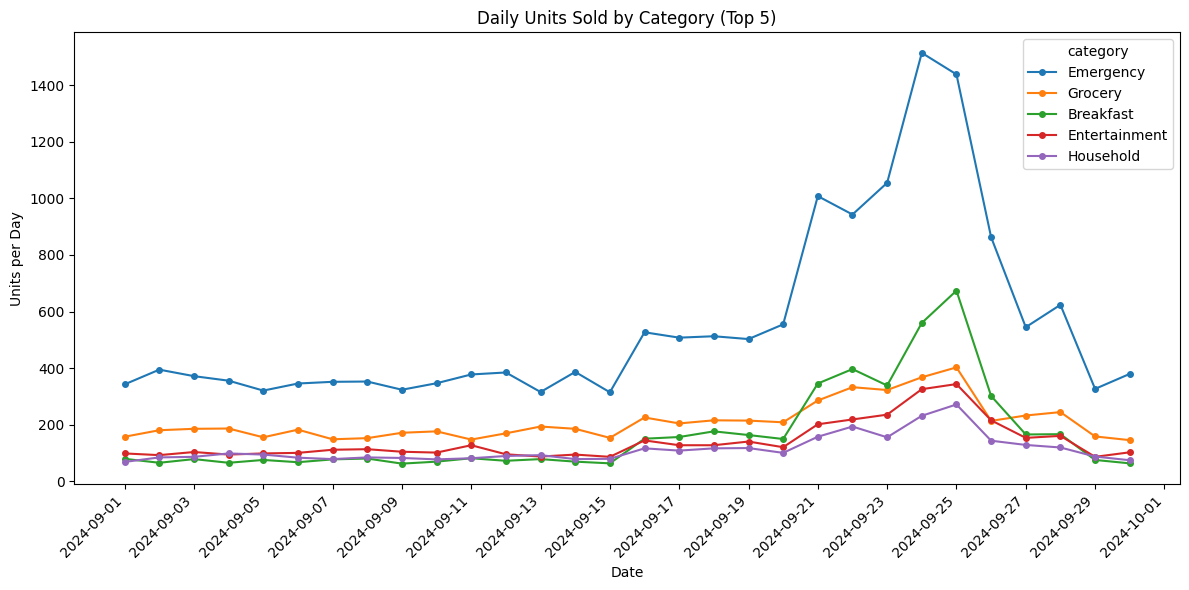

In [73]:
# Visualization of Top 5 Categories Sales over Time
daily = (trans.groupby(["date", "category"])["quantity"].sum()
              .unstack("category").fillna(0))

top5 = daily.sum().nlargest(5).index

fig, ax = plt.subplots(figsize=(12, 6))
daily[top5].plot(ax=ax, x_compat=True, marker="o", markersize=4)

ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
plt.xticks(rotation=45, ha="right")

ax.set_title("Daily Units Sold by Category (Top 5)")
ax.set_xlabel("Date")
ax.set_ylabel("Units per Day")
plt.tight_layout()
plt.show()

Q2: SKU Consolidation - Done in the above cleaning

Q3: Weather Correlation - The API call, timezone alignment, a checked join, then correlation and lag

source: open-meteo
matches the saved copy: False
_merge
both          30
left_only      0
right_only     0
Name: count, dtype: int64
weather days with no sales, dropped on purpose by the left join: 0
an outer join would have added 0 right_only rows with no sales
all three checks passed
baseline: 1091.2 orders/day over 8 days
surge:    3504.0 orders/day over 3 days
multiple: 3.2 x

Same data, different windows:
3.2x  baseline Sept 8-15, surge Sept 23-25 (ours)
2.4x  baseline Sept 8-22 (runs through the climb)
3.1x  surge Sept 24-26 (includes landfall day)
orders vs wind 0 day(s) later:  r = 0.38
orders vs wind 1 day(s) later:  r = 0.68
orders vs wind 2 day(s) later:  r = 0.83
orders vs wind 3 day(s) later:  r = 0.69
orders vs wind 4 day(s) later:  r = 0.47


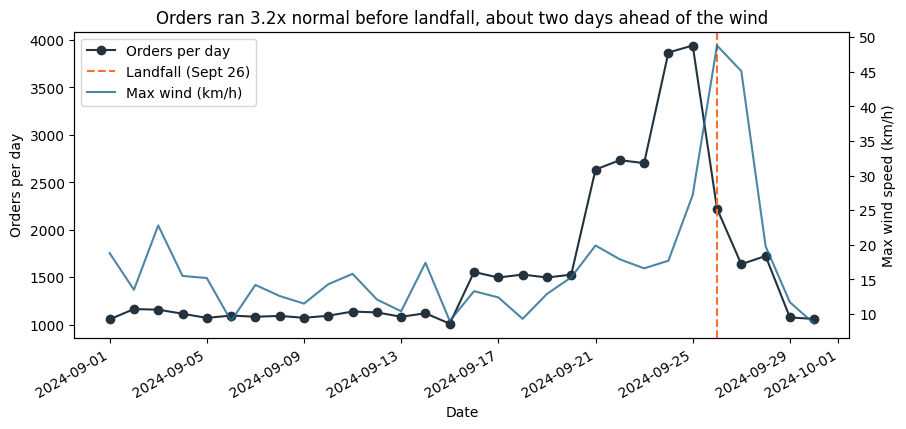

In [76]:
# Load in API
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()                       # any other bad status fails loudly
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

# A saved copy of the same Open-Meteo data (Orlando, Sept 1-30, 2024) for when you have no wifi
# or the API is down. The source column says so.
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'source': 'fallback sample',
})

try:
    weather_live = daily_weather('2024-09-01', '2024-09-30')
except requests.RequestException as err:
    print('API call failed:', err)
    weather_live = FALLBACK

same = (np.allclose(weather_live['precipitation_sum'], FALLBACK['precipitation_sum'])
        and np.allclose(weather_live['windspeed_10m_max'], FALLBACK['windspeed_10m_max']))
print('source:', weather_live['source'].iloc[0])
print('matches the saved copy:', same)

# Creating a sales table that only includes data on total sales per day
sales = trans.groupby('date')['quantity'].sum().reset_index()
sales = sales.rename(columns={'quantity': 'sales'})

# Adding in landfall date
LANDFALL = pd.Timestamp('2024-09-26')

# API Join and Merge
weather = weather_live        # works whether it came from the API or the saved copy

merged = sales.merge(weather, on='date', how='left', indicator=True)

assert len(merged) == len(sales), 'the join changed the row count'
assert not (merged['_merge'] == 'right_only').any(), 'weather rows with no sales day'   # a left join can't make these; this guards against someone changing how= later
assert merged['sales'].sum() == sales['sales'].sum(), 'the sales total changed'

outer = sales.merge(weather, on='date', how='outer', indicator=True)

print(merged['_merge'].value_counts())
print('weather days with no sales, dropped on purpose by the left join:', len(weather) - len(sales))
print('an outer join would have added', (outer['_merge'] == 'right_only').sum(), 'right_only rows with no sales')
print('all three checks passed')

# Getting correlation/surge/baseline data
def window(df, start, end):
    return df[(df['date'] >= start) & (df['date'] <= end)]

baseline = window(merged, '2024-09-08', '2024-09-15')    # flat, before the first rise
surge = window(merged, '2024-09-23', '2024-09-25')       # the three days before landfall

baseline_per_day = baseline['sales'].mean()
surge_per_day = surge['sales'].mean()
multiple = surge_per_day / baseline_per_day

print('baseline:', round(baseline_per_day, 1), 'orders/day over', len(baseline), 'days')
print('surge:   ', round(surge_per_day, 1), 'orders/day over', len(surge), 'days')
print('multiple:', round(multiple, 1), 'x')

print()
print('Same data, different windows:')
choices = {
    'baseline Sept 8-15, surge Sept 23-25 (ours)': ('2024-09-08', '2024-09-15', '2024-09-23', '2024-09-25'),
    'baseline Sept 8-22 (runs through the climb)': ('2024-09-08', '2024-09-22', '2024-09-23', '2024-09-25'),
    'surge Sept 24-26 (includes landfall day)':    ('2024-09-08', '2024-09-15', '2024-09-24', '2024-09-26'),
}
for name, (b0, b1, s0, s1) in choices.items():
    m = window(merged, s0, s1)['sales'].mean() / window(merged, b0, b1)['sales'].mean()
    print(f'{m:.1f}x  {name}')


# Lag purchasing
for k in range(0, 5):
    r = merged['sales'].corr(merged['windspeed_10m_max'].shift(-k))
    print(f'orders vs wind {k} day(s) later:  r = {r:.2f}')

# Sales and Windspeed Graph
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(merged['date'], merged['sales'], marker='o', color='#24323E', label='Orders per day')
ax.axvline(LANDFALL, color='#F67132', linestyle='--', label='Landfall (Sept 26)')
ax.set_xlabel('Date')
ax.set_ylabel('Orders per day')

ax2 = ax.twinx()
ax2.plot(merged['date'], merged['windspeed_10m_max'], color='#21688D', alpha=0.8, label='Max wind (km/h)')
ax2.set_ylabel('Max wind speed (km/h)')

ax.set_title(f'Orders ran {multiple:.1f}x normal before landfall, about two days ahead of the wind')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left')
fig.autofmt_xdate()
plt.show()

Q4: Stores and Geography - Store ids cleaned so the store file joins, then a comparison across stores

Q5: Signal or Artifact - SQL queries on the inventory database, a cross-check against the transactions, and a recommendation